# 06 — Hyper-parameter Tuning

**Method.** `RandomizedSearchCV` samples a fixed number of hyper-parameter combinations and scores each on the same
**5 expanding one-month-ahead folds** used throughout (validate on Jan … May 2024, train only on earlier months).
The **test period (Jun–Oct 2024) is never used** during tuning. Candidates are ranked by **mean validation MAE (kWh)**.

**Why random search?** A full grid over 6–9 settings would need thousands of fits; random search covers wide ranges
with a laptop-sized budget (12–30 candidates × 5 folds per model) and is known to find good settings efficiently when
only a few settings really matter.

**What is new compared with notebook 05:** the search also chooses the **loss function** (squared vs absolute error /
Huber) and whether to train on **log(1 + kWh)**. The untuned models all minimised squared error, which targets RMSE,
while this project selects models by MAE.

The searches are run by `scripts/tune_models.py` (≈ 1 hour in total); this notebook reads their saved results.
The tuned models are then evaluated by `scripts/run_experiments.py tuned` with the same CV + rolling test procedure.

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import plot_style as ps
from src.data_loader import CONSUMPTION_UNIT as U
from src.models import make_pipeline, MODEL_INFO
from src.train import load_modelling_data, run_model, load_summaries, load_test_predictions, load_cv
from src.evaluate import regression_metrics, per_month_metrics
ps.apply(); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
F, train, test = load_modelling_data()
print(f"Training rows: {len(train):,} ({train.month.min():%Y-%m}…{train.month.max():%Y-%m}) | "
      f"test rows: {len(test):,} ({test.month.min():%Y-%m}…{test.month.max():%Y-%m}) | unit: {U}")

Training rows: 68,485 (2023-01…2024-05) | test rows: 20,094 (2024-06…2024-10) | unit: kWh


## 1. Search spaces and why these ranges

In [2]:
sys.path.insert(0, str(ROOT / "scripts"))
from tune_models import SEARCH_SPACES
def describe(v):
    if isinstance(v, list): return ", ".join(map(str, v))
    d = v.dist.name; a = v.args
    return {"loguniform": f"log-uniform {a[0]}–{a[1]}", "randint": f"integers {a[0]}–{a[1]-1}", "uniform": f"uniform {a[0]}–{a[0]+a[1]}"}.get(d, str(v))
rows = [{"model": m, "parameter": p.replace("model__regressor__", "").replace("model__log", "log target"),
         "values searched": describe(v), "candidates": cfg["n_iter"]} for m, cfg in SEARCH_SPACES.items() for p, v in cfg["space"].items()]
pd.DataFrame(rows).set_index(["model", "parameter"])

values searched  candidates
model             parameter                                                         
random_forest     n_estimators                                  150, 300          12
                  min_samples_leaf                         5, 10, 20, 40          12
                  max_features                       0.33, 0.5, 0.8, 1.0          12
                  max_depth                                 None, 12, 20          12
                  max_samples                             0.5, 0.8, None          12
                  log target                                 False, True          12
extra_trees       n_estimators                                  150, 300          12
                  min_samples_leaf                         5, 10, 20, 40          12
                  max_features                       0.33, 0.5, 0.8, 1.0          12
                  max_depth                                 None, 12, 20          12
                  log target                                 False, True          12
gradient_boosting loss              squared_error, absolute_error, huber          16
                  n_estimators                        100, 200, 400, 600          16
                  learning_rate                     log-uniform 0.02–0.2          16
                  max_depth                                 integers 2–5          16
                  subsample                              uniform 0.6–1.0          16
                  min_samples_leaf                        1, 10, 30, 100          16
                  log target                                 False, True          16
xgboost           objective          reg:squarederror, reg:absoluteerror          30
                  n_estimators                       200, 400, 800, 1200          30
                  learning_rate                     log-uniform 0.01–0.2          30
                  max_depth                                 integers 3–8          30
                  subsample                              uniform 0.6–1.0          30
                  colsample_bytree                       uniform 0.5–1.0          30
                  min_child_weight                      1, 5, 10, 20, 50          30
                  reg_lambda                          log-uniform 0.1–50          30
                  log target                                 False, True          30

| Parameter | Why this range |
|---|---|
| `n_estimators` | More trees → more stable averages (bagging) or more correction steps (boosting); upper limits keep memory and time laptop-sized |
| `min_samples_leaf` / `min_child_weight` | Minimum households per leaf: larger values smooth predictions and shrink the model (forests over-fitted in notebook 05) |
| `max_features` / `colsample_bytree` | Fewer features per split → less correlated trees → better averaging |
| `max_depth` | Boosting uses shallow trees (2–8); forests also tried with depth limits |
| `learning_rate` | Log scale because its effect is multiplicative; smaller rates need more trees |
| `subsample` / `max_samples` | Row sampling adds randomness that reduces over-fitting |
| `reg_lambda` | XGBoost L2 penalty on leaf values (log scale) |
| `loss` / `objective` | Absolute error optimises MAE directly; Huber is a compromise; squared error optimises RMSE |
| log target | Reduces the influence of the few very large households |

## 2. Best settings found

In [3]:
best = json.loads((ROOT / "artifacts/tuning/best_params.json").read_text())
bp = pd.DataFrame({m: {"log target": b["log"], **b["params"], "validation MAE": round(b["cv_MAE"], 3),
                       "validation RMSE": round(b["cv_RMSE"], 2), "candidates": b["n_candidates"],
                       "search minutes": round(b["search_seconds"] / 60, 1)} for m, b in best.items()}).T
bp.T

,xgboost,gradient_boosting,extra_trees,random_forest
log target,True,True,False,False
colsample_bytree,0.759395,NaN,NaN,NaN
learning_rate,0.082158,0.025044,NaN,NaN
max_depth,3,5,None,20
min_child_weight,1,NaN,NaN,NaN
n_estimators,400,600,150,150
objective,reg:absoluteerror,NaN,NaN,NaN
reg_lambda,0.463779,NaN,NaN,NaN
subsample,0.878522,0.798071,NaN,NaN
validation MAE,19.054,18.907,19.245,19.226


## 3. What mattered in the search?

In [4]:
frames = []
for m in best:
    s = pd.read_csv(ROOT / f"artifacts/tuning/{m}_search.csv")
    loss_col = [c for c in s.columns if c.endswith("__loss") or c.endswith("__objective")]
    s["loss"] = s[loss_col[0]] if loss_col else "squared_error"
    s["model"] = m; s["log_target"] = s["param_model__log"]
    frames.append(s[["model", "loss", "log_target", "cv_MAE", "cv_RMSE", "mean_fit_time"]])
allc = pd.concat(frames)
print("Best validation MAE within each (model, loss, log target) group:")
allc.groupby(["model", "loss", "log_target"]).agg(best_cv_MAE=("cv_MAE", "min"), best_cv_RMSE=("cv_RMSE", "min"), n=("cv_MAE", "size")).round(3)

Best validation MAE within each (model, loss, log target) group:


best_cv_MAE  best_cv_RMSE   n
model             loss              log_target                               
extra_trees       squared_error     False            19.245        42.879   7
                                    True             20.106        46.563   5
gradient_boosting absolute_error    True             19.295        45.206   3
                  huber             False            19.093        44.341   2
                                    True             18.907        43.603   4
                  squared_error     False            19.079        42.412   4
                                    True             20.192        48.502   3
random_forest     squared_error     False            19.226        42.764   5
                                    True             20.143        46.505   7
xgboost           reg:absoluteerror False            19.133        46.013   9
                                    True             19.054        45.720  10
                  reg:squarederror  False            19.759        46.326   3
                                    True             19.813        48.194   8

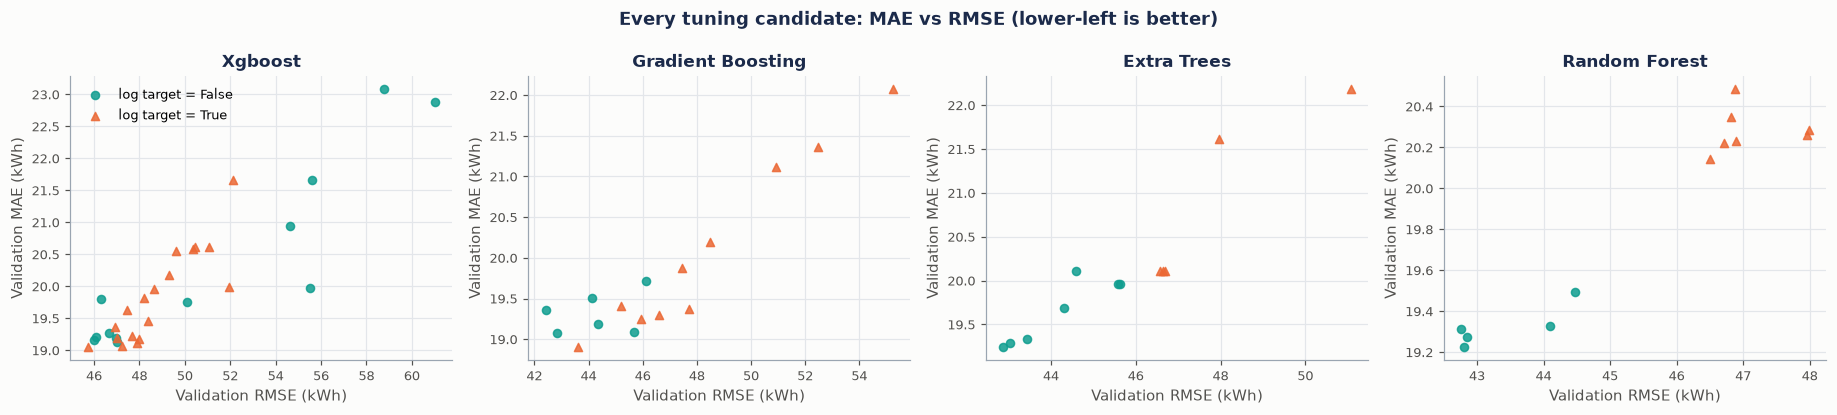

In [5]:
fig, axes = plt.subplots(1, len(best), figsize=(4.2 * len(best), 3.8), sharey=False)
for a, m in zip(axes, best):
    d = allc[allc.model == m]
    for (lg, c, mk) in [(False, ps.TEAL, "o"), (True, ps.ORANGE, "^")]:
        dd = d[d.log_target == lg]
        a.scatter(dd.cv_RMSE, dd.cv_MAE, color=c, marker=mk, s=28, label=f"log target = {lg}", alpha=0.85)
    a.set(title=m.replace("_", " ").title(), xlabel=f"Validation RMSE ({U})")
    a.set_ylabel(f"Validation MAE ({U})")
axes[0].legend(loc="upper left")
fig.suptitle("Every tuning candidate: MAE vs RMSE (lower-left is better)", color=ps.NAVY, fontweight="bold")
plt.tight_layout(); plt.show()

**Observation — what mattered.**

* **Loss function matters most for boosting.** XGBoost improved from 19.76 kWh (best squared-error candidate) to
  **19.05 kWh** with the absolute-error objective. For Gradient Boosting the best candidate used **Huber loss** (squared
  error for small residuals, absolute error for large ones) with a log target: **18.91 kWh**. Every MAE-oriented
  candidate has a *higher* RMSE than the best squared-error candidates — the expected MAE/RMSE trade-off.
* **The log target helps boosting but hurts the forests.** Random Forest and Extra Trees were ≈ 0.9 kWh worse with a log
  target (20.1–20.2 vs 19.2 kWh). Averaging many trees in log-space and converting back systematically under-predicts
  the mean (the exponential of an average is smaller than the average of exponentials), which costs accuracy for
  bagging; boosting with Huber/absolute loss is aiming at the median anyway, so the log scale fits it.
* **Forests barely improve with tuning** (Random Forest 19.43 → 19.23, Extra Trees 19.24 → 19.25). Their only loss is
  squared error, and the starting settings were already reasonable; tuning chose larger leaves for Random Forest
  (`min_samples_leaf=10`, `max_features=0.5`, depth 20), which also makes the saved model smaller.
* **Boosting prefers slow, shallow learning:** Gradient Boosting chose 600 trees with learning rate 0.025 and depth 5;
  XGBoost chose depth 3 (the untuned default depth 6 over-fitted).

## 4. Untuned vs tuned — same CV folds and the same test period

In [6]:
un = load_summaries("untuned").set_index("label"); tu = load_summaries("tuned").set_index("label")
comp = pd.DataFrame({
    "untuned val MAE": un.cv_MAE, "tuned val MAE": tu.cv_MAE,
    "untuned test MAE": un.test_MAE, "tuned test MAE": tu.test_MAE,
    "untuned test RMSE": un.test_RMSE, "tuned test RMSE": tu.test_RMSE,
    "tuned train MAE": tu.train_MAE, "tuned fit seconds": tu.fit_seconds_full}).dropna(subset=["tuned val MAE"])
comp["val MAE change"] = comp["tuned val MAE"] - comp["untuned val MAE"]
comp.sort_values("tuned val MAE").round(3)

,untuned val MAE,tuned val MAE,untuned test MAE,tuned test MAE,untuned test RMSE,tuned test RMSE,tuned train MAE,tuned fit seconds,val MAE change
label,,,,,,,,,
voting,19.105,18.780,19.757,19.675,43.712,44.988,15.842,152.588,-0.325
gradient_boosting,19.408,18.907,19.997,20.021,44.332,45.494,16.458,145.277,-0.501
stacking,19.066,18.981,19.670,19.626,43.636,43.831,16.821,1052.386,-0.084
xgboost,20.585,19.054,21.926,20.374,52.920,50.093,17.159,2.072,-1.531
random_forest,19.429,19.226,20.024,19.601,44.338,43.680,14.600,6.256,-0.203
extra_trees,19.242,19.245,20.042,20.059,44.003,44.088,12.775,5.123,0.003


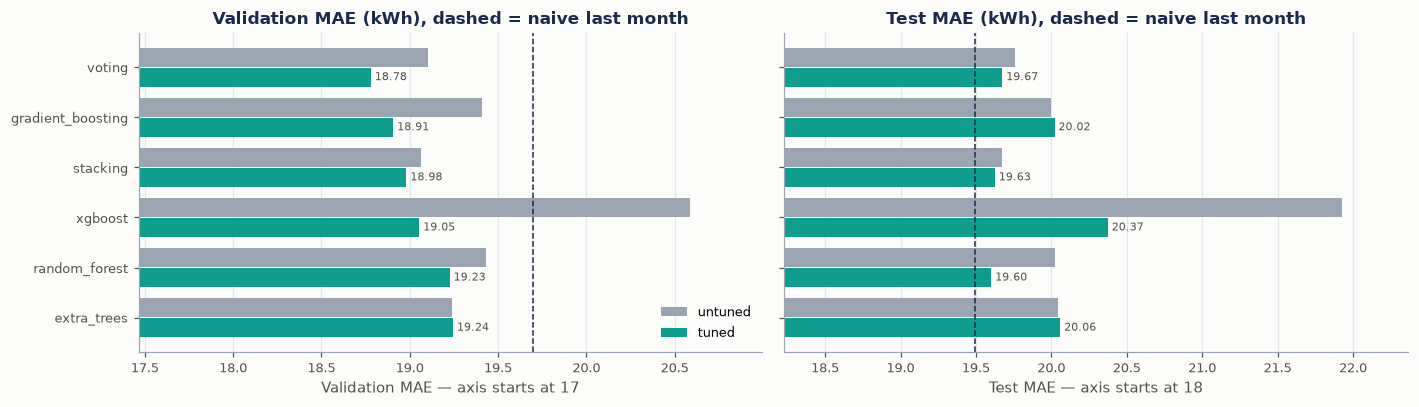

In [7]:
c = comp.sort_values("tuned val MAE")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
y = np.arange(len(c))
for a, (u, t, ttl) in zip(ax, [("untuned val MAE", "tuned val MAE", "Validation MAE"), ("untuned test MAE", "tuned test MAE", "Test MAE")]):
    a.barh(y - 0.2, c[u], height=0.38, color=ps.MUTED, label="untuned")
    a.barh(y + 0.2, c[t], height=0.38, color=ps.TEAL, label="tuned")
    a.axvline(19.695 if ttl.startswith("Val") else 19.491, color=ps.NAVY, ls="--", lw=1)
    lo = min(c[u].min(), c[t].min()) * 0.93; a.set_xlim(lo, max(c[u].max(), c[t].max()) * 1.02)
    for i, v in enumerate(c[t]): a.text(v, i + 0.2, f" {v:.2f}", va="center", fontsize=7.5, color=ps.INK_2)
    a.set(title=f"{ttl} ({U}), dashed = naive last month", xlabel=f"{ttl} — axis starts at {lo:.0f}"); a.grid(axis="y", visible=False)
ax[0].set_yticks(y); ax[0].set_yticklabels(c.index); ax[0].invert_yaxis(); ax[0].legend(loc="lower right")
plt.tight_layout(); plt.show()

**Observation — validation vs test.**

* On **validation**, tuning improved every boosting/combination model: XGBoost −1.53, Gradient Boosting −0.50, Voting
  −0.33 kWh; the best validation MAE is now **Voting 18.78 kWh** (naive 19.70).
* On the **test period** the gains largely disappear: tuned Gradient Boosting 20.02 and XGBoost 20.37 kWh are no better
  than untuned and worse than the naive forecast (19.49). Voting (19.68), Stacking (19.63) and Random Forest (19.60)
  are close to the naive forecast on MAE but clearly better on RMSE (43.7–45.0 vs 48.8).

**Why the gap?** Notebook 07 shows that most of it comes from a single test month — **October 2024** — where the
MAE-tuned boosting models under-predict by ≈ 19 kWh on average. The training data contain only one October (2023), an
unusually low month, so the models learned a spurious "October is low" pattern from the calendar-month features and
`lag_12`. Validation months (Jan–May 2024) could not reveal this. This is examined (post-hoc, clearly labelled) in
notebook 07; it is a limitation of having only ~2 years of data, not something the tuning procedure could detect.

## 5. Voting and Stacking rebuilt from tuned members

In [8]:
sel = json.loads((ROOT / "artifacts/model_selection.json").read_text())
print(json.dumps(sel, indent=2))

{
  "voting_members": [
    "gradient_boosting",
    "xgboost",
    "random_forest"
  ],
  "stacking_tree_bases": [
    "random_forest",
    "gradient_boosting"
  ],
  "final_model": "voting",
  "final_cv_MAE": 18.779777510215734,
  "rule": "lowest mean validation MAE over the 5 expanding folds (experiment 'tuned')"
}


**Observation.** Following the rules fixed in `scripts/run_experiments.py` *before* the tuned test results were seen:

* **Voting** = average of the three best tuned single ensembles by validation MAE: Gradient Boosting, XGBoost and
  Random Forest.
* **Stacking** = naive persistence + Ridge + the best bagging model (Random Forest) + the best boosting model
  (Gradient Boosting), combined by a non-negative Ridge meta-learner trained on time-ordered out-of-fold predictions.
* **Final model by the selection rule: Voting** (validation MAE 18.78 kWh — the lowest of all models).

## 6. Summary

| Model | Untuned val MAE | Tuned val MAE | Tuned test MAE | Tuned test RMSE | Chosen loss / target |
|---|---|---|---|---|---|
| **Voting (GB + XGB + RF)** | 19.11 | **18.78** | 19.68 | 44.99 | members' settings |
| Gradient Boosting | 19.41 | 18.91 | 20.02 | 45.49 | Huber, log target |
| Stacking | 19.07 | 18.98 | **19.63** | **43.83** | Ridge meta-learner |
| XGBoost | 20.59 | 19.05 | 20.37 | 50.09 | absolute error, log target |
| Random Forest | 19.43 | 19.23 | 19.60 | 43.68 | squared error |
| Extra Trees | 19.24 | 19.25 | 20.06 | 44.09 | squared error |
| *Naive last month* | — | *19.70* | *19.49* | *48.84* | — |

(kWh.) Tuning — especially choosing an MAE-friendly loss — improved validation MAE by up to 1.5 kWh for boosting, and
Voting became the best model on validation. These gains did not transfer to the test period, mainly because of one
month (October 2024) whose pattern could not be learned from a single previous October.